# View 1: Confusion Matrices, Small Multiples & Difference Maps
Analyzes systemic classification shifts under corruptions compared to clean baseline.

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import os

make CM from predictions.csv

In [13]:
df = pd.read_csv("results_card/predictions.csv")
os.makedirs("../figures/phase1_human", exist_ok=True)

df_mismatch = df[df["keras_pred"] != df["akida_pred"]] # SNN hardware disagrees with Keras sim

# get the worst 15 classes (to not show 1000 classes)
top_15_unstable = df_mismatch["keras_pred"].value_counts().head(15).index.tolist() 
df_filtered = df[df["keras_pred"].isin(top_15_unstable)].copy()

# "Other" bucket
OTHER_ID = 9999
df_filtered.loc[~df_filtered["akida_pred"].isin(top_15_unstable), "akida_pred"] = OTHER_ID
cm_labels = top_15_unstable + [OTHER_ID]
tick_labels = [str(c) for c in top_15_unstable] + ["Other"]


In [14]:
# confusion Matrix
cm = confusion_matrix(df_filtered["keras_pred"], df_filtered["akida_pred"], labels=cm_labels, normalize="true")

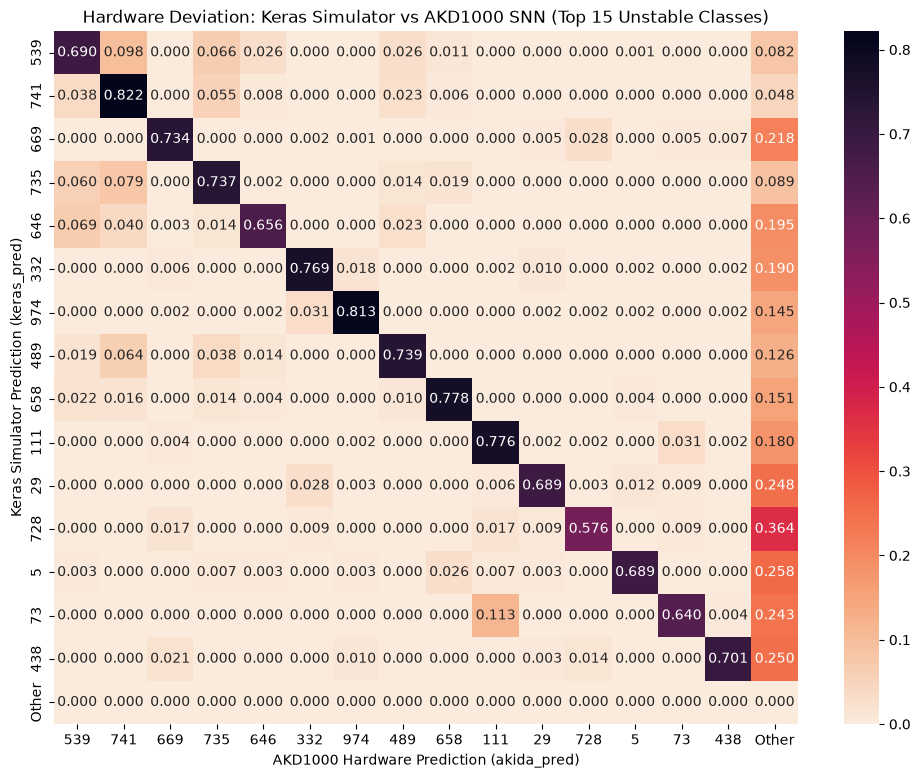

In [15]:
plt.figure(figsize=(12, 9))
sns.heatmap(cm, annot=True, fmt=".3f", cmap="rocket_r", 
            xticklabels=tick_labels, yticklabels=tick_labels)
plt.title("Hardware Deviation: Keras Simulator vs AKD1000 SNN (Top 15 Unstable Classes)")
plt.xlabel("AKD1000 Hardware Prediction (akida_pred)")
plt.ylabel("Keras Simulator Prediction (keras_pred)")
plt.savefig("../figures/phase1_human/keras_vs_akida_hardware_shift.png", bbox_inches="tight")
plt.show()